In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix
from sklearn.metrics import classification_report
import torch.nn as nn

import experiment
import clslib
import analysis
import smlp

In [2]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [3]:
vocab_size = 1000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset["sentence"], vocab_size, min_frequency)
# tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

indicator_encoder = clslib.TokenIndicator(bpe_tokenizer)

my_classifiers = OrderedDict()

In [4]:
hidden_dim=128
dropout=0.1
batch_size=64
learning_rate=1e-3
weight_decay=1e-4
num_epochs=10
device='cpu'

my_classifiers['singleMLP_indic-enc'] = []

for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/singleMLP_indic-enc/seed-{seed}"

    my_classifiers['singleMLP_indic-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=indicator_encoder,
            model_option='smlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': hidden_dim,
                'dropout': dropout,
                'batch_size': batch_size,
                'learning_rate': learning_rate,
                'weight_decay': weight_decay,
                'num_epochs': num_epochs,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 69.684 seconds
Dataloader done! Time taken: 3.329 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\Alex\Documents\A Docs\Logic\Logic courses\NLP new\NLP-Assignment-1\smlp.py:68: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.5093 | train acc: 0.7488 | val loss: 0.4184 | val acc: 0.8073
Epoch 02 | train loss: 0.3687 | train acc: 0.8387 | val loss: 0.3494 | val acc: 0.8523
Epoch 03 | train loss: 0.2889 | train acc: 0.8825 | val loss: 0.3067 | val acc: 0.8713
Epoch 04 | train loss: 0.2284 | train acc: 0.9123 | val loss: 0.2709 | val acc: 0.8893
Epoch 05 | train loss: 0.1851 | train acc: 0.9320 | val loss: 0.2532 | val acc: 0.9004
Epoch 06 | train loss: 0.1530 | train acc: 0.9452 | val loss: 0.2482 | val acc: 0.9055
Epoch 07 | train loss: 0.1313 | train acc: 0.9539 | val loss: 0.2390 | val acc: 0.9105
Epoch 08 | train loss: 0.1129 | train acc: 0.9605 | val loss: 0.2392 | val acc: 0.9134
Epoch 09 | train loss: 0.0996 | train acc: 0.9662 | val loss: 0.2428 | val acc: 0.9169
Epoch 10 | train loss: 0.0897 | train acc: 0.9699 | val loss: 0.2491 | val acc: 0.9163
Training done! Time taken: 202.123 seconds
Transforming documents...
Document transformation done! Time taken: 49.383 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.5082 | train acc: 0.7476 | val loss: 0.4307 | val acc: 0.7990
Epoch 02 | train loss: 0.3731 | train acc: 0.8347 | val loss: 0.3632 | val acc: 0.8415
Epoch 03 | train loss: 0.2936 | train acc: 0.8798 | val loss: 0.3165 | val acc: 0.8680
Epoch 04 | train loss: 0.2314 | train acc: 0.9114 | val loss: 0.2851 | val acc: 0.8876
Epoch 05 | train loss: 0.1880 | train acc: 0.9299 | val loss: 0.2680 | val acc: 0.8964
Epoch 06 | train loss: 0.1565 | train acc: 0.9431 | val loss: 0.2592 | val acc: 0.9018
Epoch 07 | train loss: 0.1330 | train acc: 0.9530 | val loss: 0.2550 | val acc: 0.9085
Epoch 08 | train loss: 0.1151 | train acc: 0.9599 | val loss: 0.2530 | val acc: 0.9105
Epoch 09 | train loss: 0.1010 | train acc: 0.9655 | val loss: 0.2553 | val acc: 0.9112
Epoch 10 | train loss: 0.0896 | train acc: 0.9696 | val loss: 0.2693 | val acc: 0.9106
Training done! Time taken: 121.883 seconds
Transforming documents...
Document transformation done! Time taken: 40.224 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.5084 | train acc: 0.7485 | val loss: 0.4302 | val acc: 0.8041
Epoch 02 | train loss: 0.3732 | train acc: 0.8359 | val loss: 0.3595 | val acc: 0.8471
Epoch 03 | train loss: 0.2943 | train acc: 0.8794 | val loss: 0.3105 | val acc: 0.8707
Epoch 04 | train loss: 0.2328 | train acc: 0.9100 | val loss: 0.2791 | val acc: 0.8874
Epoch 05 | train loss: 0.1871 | train acc: 0.9302 | val loss: 0.2637 | val acc: 0.8973
Epoch 06 | train loss: 0.1551 | train acc: 0.9436 | val loss: 0.2563 | val acc: 0.9016
Epoch 07 | train loss: 0.1327 | train acc: 0.9531 | val loss: 0.2516 | val acc: 0.9070
Epoch 08 | train loss: 0.1140 | train acc: 0.9605 | val loss: 0.2476 | val acc: 0.9076
Epoch 09 | train loss: 0.0996 | train acc: 0.9663 | val loss: 0.2532 | val acc: 0.9111
Epoch 10 | train loss: 0.0890 | train acc: 0.9706 | val loss: 0.2588 | val acc: 0.9122
Training done! Time taken: 156.241 seconds


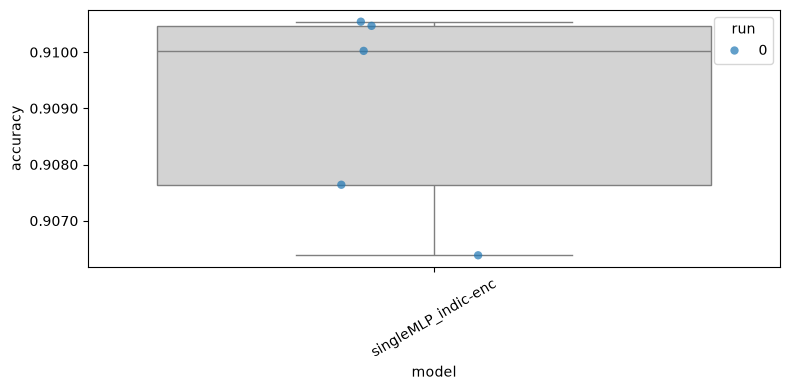

In [5]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [6]:
testing_sentences = test_dataset["sentence"]
testing_vectors = [indicator_encoder(text) for text in testing_sentences]
testing_labels = test_dataset["label"]
X_test_sparse = csr_matrix(testing_vectors)
test_dataset_sparse = smlp.SparseDataset(X_test_sparse, testing_labels)

test_loader = DataLoader(
        test_dataset_sparse,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=smlp.sparse_collate
    )

criterion = nn.BCEWithLogitsLoss()

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):    
        model_folder = f"{results_folder}/singleMLP_indic-enc/seed-{seed}/fold-{fold}/model"
        model = smlp.load(model_folder)

        smlp.evaluate(model, test_loader, criterion, device)
        test_metrics, preds = smlp.evaluate(model, test_loader, criterion, device)
        print(test_metrics)
        print(classification_report(testing_labels, preds))

{'loss': 0.6496583529568594, 'accuracy': 0.7786697247706422}
              precision    recall  f1-score   support

           0       0.78      0.76      0.77       428
           1       0.77      0.80      0.79       444

    accuracy                           0.78       872
   macro avg       0.78      0.78      0.78       872
weighted avg       0.78      0.78      0.78       872

{'loss': 0.7059142928604686, 'accuracy': 0.7729357798165137}
              precision    recall  f1-score   support

           0       0.78      0.75      0.76       428
           1       0.77      0.80      0.78       444

    accuracy                           0.77       872
   macro avg       0.77      0.77      0.77       872
weighted avg       0.77      0.77      0.77       872

{'loss': 0.7058811931435122, 'accuracy': 0.7844036697247706}
              precision    recall  f1-score   support

           0       0.80      0.75      0.77       428
           1       0.77      0.82      0.79       444


In [8]:
# save results
Path("metrics").mkdir(exist_ok=True)

df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)